<a href="https://colab.research.google.com/github/Danylo5051/machine-learning-practice/blob/main/%D0%A1%D0%B0%D1%82%D0%BA%D0%BE%D0%94_4%D0%BA9%D0%B3%D0%9B%D0%A0_8_%D0%9C%D0%9D_%D0%9A%D0%BB%D0%B0%D1%81%D1%82%D0%B5%D1%80%D0%B8%D0%B7%D0%B0%D1%86%D1%96%D1%8F.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [2]:
iris = load_iris()
X = iris.data

pd.DataFrame(X, columns=iris.feature_names).head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

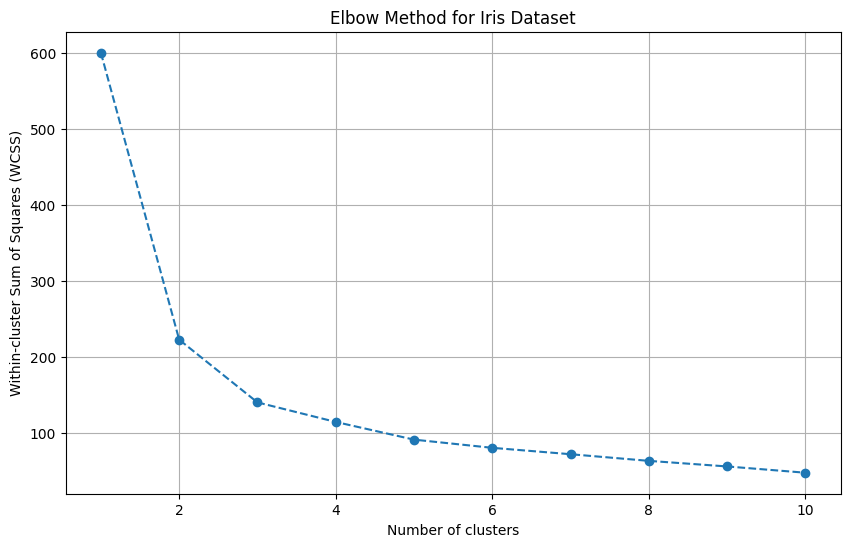

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_iris = pd.DataFrame(X_scaled, columns=iris.feature_names)

# Метод ліктя
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++',
                    max_iter=300, n_init=10, random_state=0)
    kmeans.fit(X_iris)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Elbow Method for Iris Dataset')
plt.xlabel('Number of clusters')
plt.ylabel('Within-cluster Sum of Squares (WCSS)')
plt.grid(True)
plt.show()

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

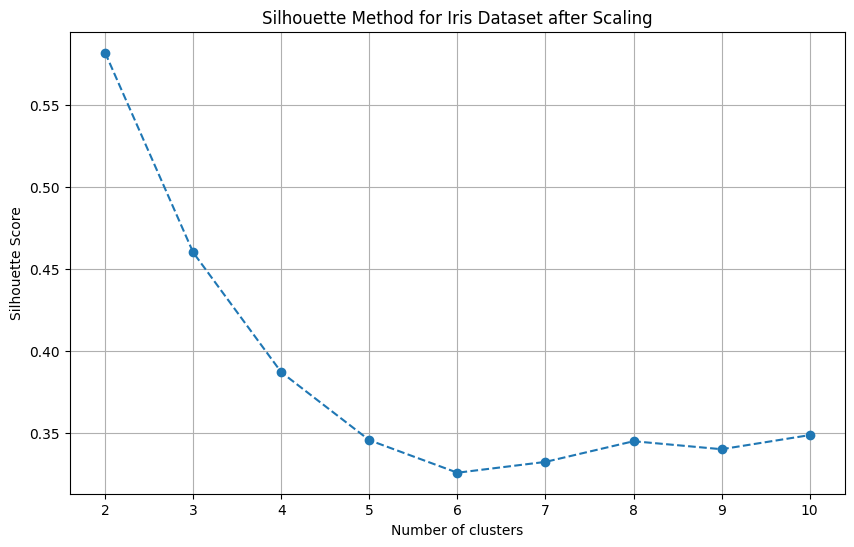

In [4]:
silhouette_scores = []
for i in range(2, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=0)
    cluster_labels = kmeans.fit_predict(X_iris)
    silhouette_avg = silhouette_score(X_iris, cluster_labels)
    silhouette_scores.append(silhouette_avg)

plt.figure(figsize=(10, 6))
plt.plot(range(2, 11), silhouette_scores, marker='o', linestyle='--')
plt.title('Silhouette Method for Iris Dataset after Scaling')
plt.xlabel('Number of clusters')
plt.ylabel('Silhouette Score')
plt.grid(True)
plt.show()

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

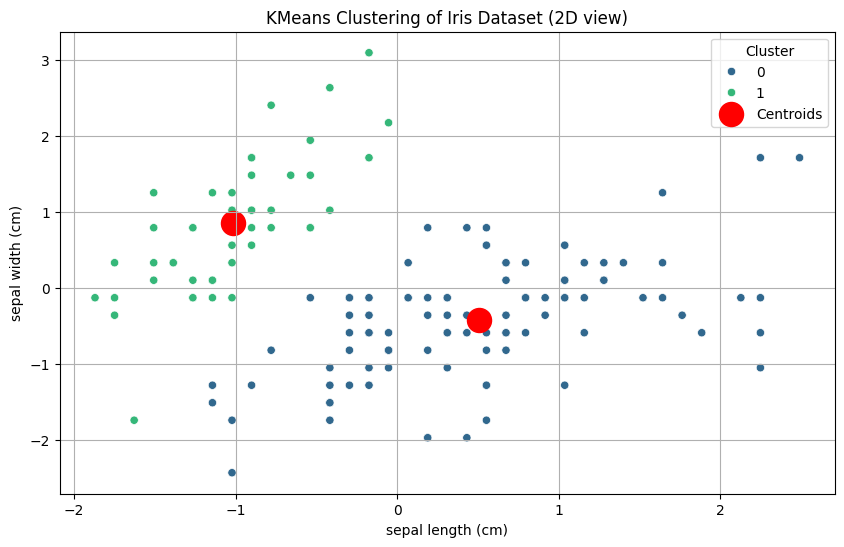

In [5]:
kmeans = KMeans(n_clusters=2, init='k-means++', max_iter=300, n_init=10, random_state=42)
clusters = kmeans.fit_predict(X_iris)

plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_iris.iloc[:, 0], y=X_iris.iloc[:, 1], hue=clusters,
                palette='viridis', legend='full')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            s=300, c='red', label='Centroids')
plt.title('KMeans Clustering of Iris Dataset (2D view)')
plt.xlabel(iris.feature_names[0])
plt.ylabel(iris.feature_names[1])
plt.legend(title='Cluster')
plt.grid(True)
plt.show()

**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

За результатами дослідження, метод ліктя демонструє найстрімкіше падіння інерції при переході від 1 до 2 кластерів, після чого крива стає значно пологішою (з невеликим перегином на K=3). Натомість метод силуетів дає абсолютно однозначну оцінку: чіткий глобальний максимум коефіцієнта (близько 0.58) досягається саме при K=2. Отже, вибір двох кластерів для фінальної моделі повністю збігається з отриманими графіками та є математично найдоцільнішим. Двовимірна візуалізація розбиття підтверджує цей поділ: алгоритм K-Means успішно виділив один візуально ізольований кластер, а два інші види об'єднав у другий великий кластер через їхню високу геометричну подібність і перекриття ознак у просторі.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [7]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [8]:
# Вивід даних з файлу
df = pd.read_csv(os.path.join(path,'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [9]:
print(df.columns.tolist())

['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [11]:
print(df.isnull().sum())

StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [12]:
print(f"Кількість дублікатів: {df.duplicated().sum()}")

Кількість дублікатів: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [13]:
df.describe()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [14]:
X = df.drop(columns=['GradeClass', 'StudentID'])
y = df['GradeClass']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [15]:
rf_param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

rf_model = RandomForestClassifier(random_state=42)
rf_grid = GridSearchCV(rf_model, rf_param_grid, cv=5, scoring='accuracy', n_jobs=-1)

rf_grid.fit(X_train_scaled, y_train)

best_rf = rf_grid.best_estimator_
y_pred_rf = best_rf.predict(X_test_scaled)

print("Найкращі гіперпараметри Random Forest:", rf_grid.best_params_)
print("Середня крос-валідаційна точність (CV accuracy):", f"{rf_grid.best_score_:.4f}")
print("Тестова точність (Test accuracy):", f"{accuracy_score(y_test, y_pred_rf):.4f}")

Найкращі гіперпараметри Random Forest: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Середня крос-валідаційна точність (CV accuracy): 0.9237
Тестова точність (Test accuracy): 0.9144


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [16]:
lr_param_grid = {
    'C': [0.1, 1, 10],
    'max_iter': [1000]
}

lr_model = LogisticRegression(solver='saga', random_state=42)
lr_grid = GridSearchCV(lr_model, lr_param_grid, cv=5, scoring='accuracy', n_jobs=-1)

lr_grid.fit(X_train_scaled, y_train)

best_lr = lr_grid.best_estimator_
y_pred_lr = best_lr.predict(X_test_scaled)

print("Найкращі гіперпараметри Logistic Regression:", lr_grid.best_params_)
print("Середня крос-валідаційна точність (CV accuracy):", f"{lr_grid.best_score_:.4f}")
print("Тестова точність (Test accuracy):", f"{accuracy_score(y_test, y_pred_lr):.4f}")

Найкращі гіперпараметри Logistic Regression: {'C': 10, 'max_iter': 1000}
Середня крос-валідаційна точність (CV accuracy): 0.7898
Тестова точність (Test accuracy): 0.7432


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [17]:
svm_param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf']
}

svm_model = SVC(random_state=42)
svm_grid = GridSearchCV(svm_model, svm_param_grid, cv=5, scoring='accuracy', n_jobs=-1)
svm_grid.fit(X_train_scaled, y_train)

print("Найкращі гіперпараметри SVM:", svm_grid.best_params_)
print("Середня CV-точність SVM:", f"{svm_grid.best_score_:.4f}")
print("Тестова точність SVM:", f"{accuracy_score(y_test, svm_grid.best_estimator_.predict(X_test_scaled)):.4f}")

Найкращі гіперпараметри SVM: {'C': 10, 'kernel': 'linear'}
Середня CV-точність SVM: 0.8620
Тестова точність SVM: 0.8288


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [18]:
models_cv = {
    'Random Forest': rf_grid,
    'Logistic Regression': lr_grid,
    'SVM': svm_grid
}

print("--- Порівняння тестової точності трьох моделей ---")
for name, grid in models_cv.items():
    test_acc = accuracy_score(y_test, grid.best_estimator_.predict(X_test_scaled))
    print(f"{name}: Тестова = {test_acc:.4f} (CV = {grid.best_score_:.4f})")

best_model_name = max(models_cv, key=lambda k: models_cv[k].best_score_)
best_final_model = models_cv[best_model_name].best_estimator_

print(f"\nМодель за найкращою CV-точністю: {best_model_name}")

y_pred_best = best_final_model.predict(X_test_scaled)
print("\nClassification Report (на тестових даних):")
print(classification_report(y_test, y_pred_best))

--- Порівняння тестової точності трьох моделей ---
Random Forest: Тестова = 0.9144 (CV = 0.9237)
Logistic Regression: Тестова = 0.7432 (CV = 0.7898)
SVM: Тестова = 0.8288 (CV = 0.8620)

Модель за найкращою CV-точністю: Random Forest

Classification Report (на тестових даних):
              precision    recall  f1-score   support

         0.0       0.83      0.45      0.59        22
         1.0       0.81      0.88      0.84        49
         2.0       0.94      0.87      0.90        85
         3.0       0.90      0.90      0.90        86
         4.0       0.94      0.99      0.96       237

    accuracy                           0.91       479
   macro avg       0.88      0.82      0.84       479
weighted avg       0.91      0.91      0.91       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

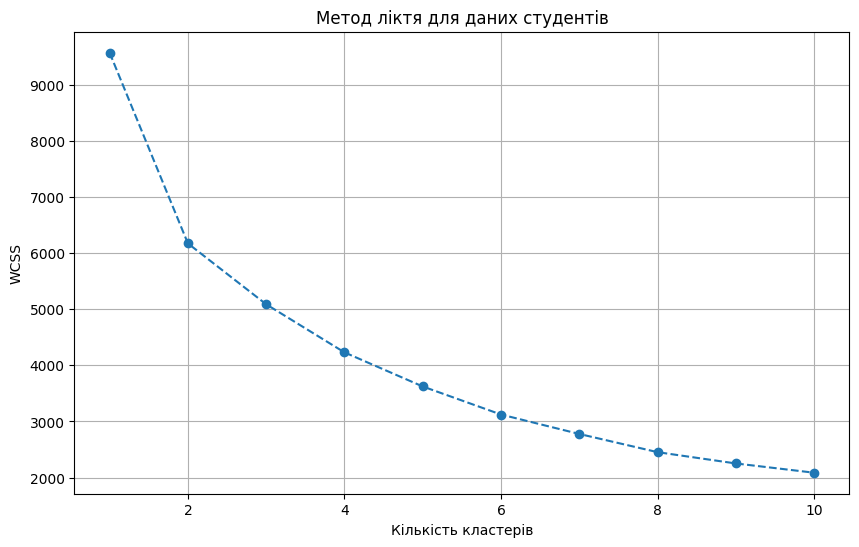

In [19]:
features_clust = ['Age', 'StudyTimeWeekly', 'Absences', 'GPA']
X_clust = df[features_clust]

scaler_clust = StandardScaler()
X_clust_scaled = scaler_clust.fit_transform(X_clust)

wcss_students = []
for i in range(1, 11):
    kmeans_s = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=42)
    kmeans_s.fit(X_clust_scaled)
    wcss_students.append(kmeans_s.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss_students, marker='o', linestyle='--')
plt.title('Метод ліктя для даних студентів')
plt.xlabel('Кількість кластерів')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

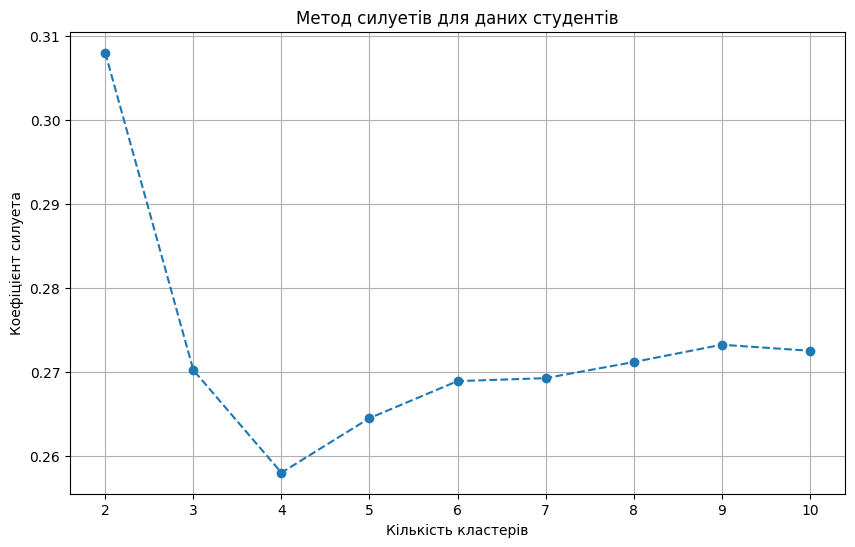

In [20]:
silhouette_scores_students = []
for i in range(2, 11):
    kmeans_s = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=42)
    cluster_labels_s = kmeans_s.fit_predict(X_clust_scaled)
    silhouette_scores_students.append(silhouette_score(X_clust_scaled, cluster_labels_s))

plt.figure(figsize=(10, 6))
plt.plot(range(2, 11), silhouette_scores_students, marker='o', linestyle='--')
plt.title('Метод силуетів для даних студентів')
plt.xlabel('Кількість кластерів')
plt.ylabel('Коефіцієнт силуета')
plt.grid(True)
plt.show()

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [21]:
!pip install kneed yellowbrick

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [22]:
from sklearn.decomposition import PCA
from kneed import KneeLocator
import numpy as np

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [23]:
X_pca = df.drop(columns=['StudentID', 'GradeClass'])

**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [24]:
scaler_pca = StandardScaler()
X_pca_scaled = scaler_pca.fit_transform(X_pca)

pca = PCA()
pca.fit(X_pca_scaled)

explained_variance = pca.explained_variance_ratio_
print("Частки поясненої дисперсії:\n", explained_variance)

Частки поясненої дисперсії:
 [0.15246911 0.0861136  0.08267885 0.08071826 0.07864825 0.07793075
 0.0763079  0.07600434 0.07440892 0.0737979  0.07167781 0.06746103
 0.00178329]


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

Автоматично визначена точка ліктя: 1


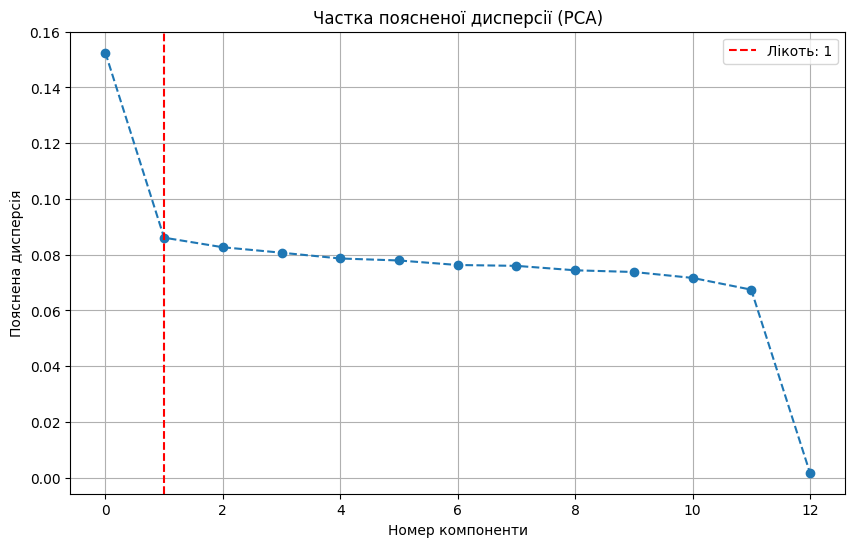

In [26]:
components = np.arange(len(explained_variance))

kneedle = KneeLocator(components, explained_variance, curve='convex', direction='decreasing')
elbow_point = kneedle.elbow

print(f"Автоматично визначена точка ліктя: {elbow_point}")

plt.figure(figsize=(10, 6))
plt.plot(components, explained_variance, marker='o', linestyle='--')
plt.axvline(x=elbow_point, color='red', linestyle='--', label=f'Лікоть: {elbow_point}')
plt.title('Частка поясненої дисперсії (PCA)')
plt.xlabel('Номер компоненти')
plt.ylabel('Пояснена дисперсія')
plt.legend()
plt.grid(True)
plt.show()

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

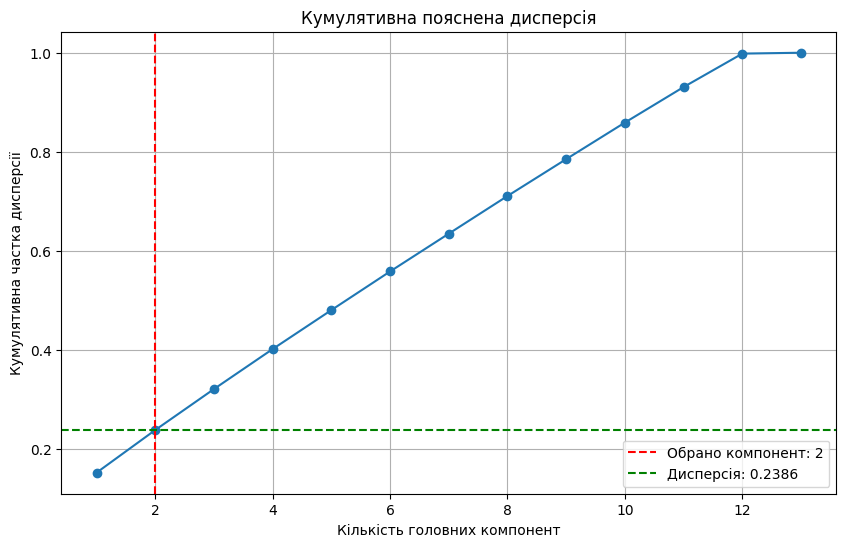

Фактична частка кумулятивної дисперсії для 2 компонент: 0.2386


In [29]:
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

n_components = elbow_point + 1
actual_variance = cumulative_variance[n_components - 1]

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='-')
plt.axvline(x=n_components, color='red', linestyle='--', label=f'Обрано компонент: {n_components}')
plt.axhline(y=actual_variance, color='green', linestyle='--', label=f'Дисперсія: {actual_variance:.4f}')

plt.title('Кумулятивна пояснена дисперсія')
plt.xlabel('Кількість головних компонент')
plt.ylabel('Кумулятивна частка дисперсії')
plt.legend()
plt.grid(True)
plt.show()

print(f"Фактична частка кумулятивної дисперсії для {n_components} компонент: {actual_variance:.4f}")

pca_final = PCA(n_components=n_components)
X_pca_transformed = pca_final.fit_transform(X_pca_scaled)

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [30]:
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

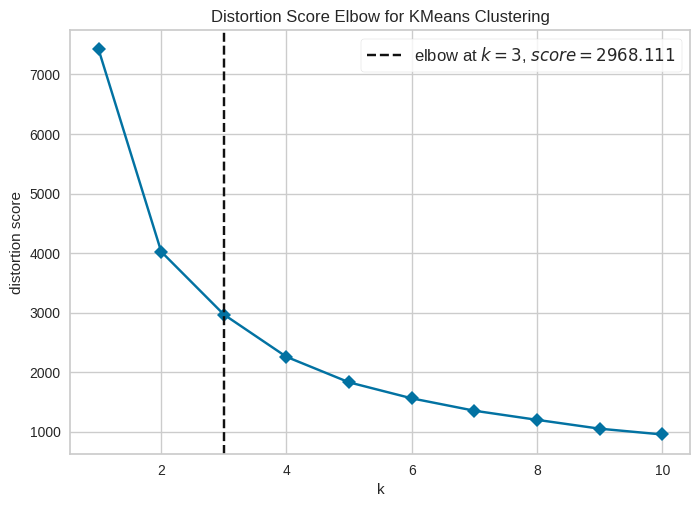

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [31]:
kmeans_pca = KMeans(init='k-means++', max_iter=300, n_init=10, random_state=42)

visualizer = KElbowVisualizer(kmeans_pca, k=(1, 11), timings=False)

visualizer.fit(X_pca_transformed)
visualizer.show()

## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.

У класифікації для прогнозування використовується цільова змінна GradeClass, тоді як кластеризація її ігнорує, об'єднуючи студентів виключно за математичною подібністю ознак. Алгоритм PCA автоматично виділив 2 головні компоненти, які сумарно пояснюють 23.86% дисперсії. Щодо визначення кількості кластерів, базовий метод ліктя не показав чіткого перегину через плавне спадання кривої. Натомість метод силуетів однозначно визначив 2 кластери як оптимальний поділ, тоді як автоматизований метод ліктя після стиснення ознак через PCA вказав на 3 кластери.